<a href="https://colab.research.google.com/github/simackinch-art/1/blob/main/normalization_and_pipline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Breast Cancer Classification Project

## Project Description
This educational project focuses on data preprocessing and building a machine learning model for breast cancer diagnosis.

**Task:** Build a model that determines whether a tumor is malignant or benign based on the morphological features of cells (size, texture, symmetry, etc.).

**Why it matters:** In medical diagnostics, missing a disease (False Negative) is far more critical than a false alarm (False Positive). Therefore, we will evaluate not only the overall accuracy but also the recall.

## Tools Used
*   Python (Pandas, NumPy)
*   Scikit-learn (LogisticRegression, Scalers, Pipeline)
*   Matplotlib (Visualization)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline, make_pipeline

## Array

In [2]:
data = load_breast_cancer()
type(data)

sklearn.utils._bunch.Bunch

In [3]:
X, y = data.data, data.target
X.shape, y.shape

((569, 30), (569,))

In [4]:
print(data.DESCR)

.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [5]:
pd.DataFrame(X, columns=data.feature_names).head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
counts = pd.Series(y).value_counts()
counts

,count
1,357
0,212


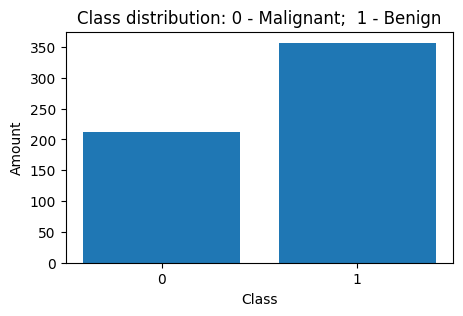

In [7]:
plt.figure(figsize=(5, 3))
plt.bar(counts.index, counts.values)
plt.title('Class distribution: 0 - Malignant;  1 - Benign')
plt.xlabel('Class')
plt.ylabel('Amount')
plt.xticks([0, 1])
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train.shape[0], X_test.shape[0]

(426, 143)

In [9]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

In [10]:
model.intercept_, model.coef_

(array([31.36693873]),
 array([[ 1.08019387e+00,  2.34193779e-01, -4.22027058e-01,
          2.85814344e-02, -1.38673752e-01, -2.44088014e-01,
         -5.19286532e-01, -2.76231408e-01, -2.14444037e-01,
         -3.98208027e-02, -1.25239345e-01,  1.42761701e+00,
          3.91365647e-01, -1.42343232e-01, -1.90407306e-02,
          3.58276533e-03, -6.90809699e-02, -3.41921459e-02,
         -4.32964644e-02,  5.56630236e-04,  1.10169289e-01,
         -5.12309657e-01, -3.99475580e-02, -1.35965155e-02,
         -2.83119663e-01, -7.66819298e-01, -1.38779452e+00,
         -4.94652902e-01, -7.23109808e-01, -1.05951256e-01]]))

In [11]:
y_test_pred = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, y_test_pred)
accuracy

0.965034965034965

In [12]:
f1 = metrics.f1_score(y_test, y_test_pred)
f1

0.9720670391061452

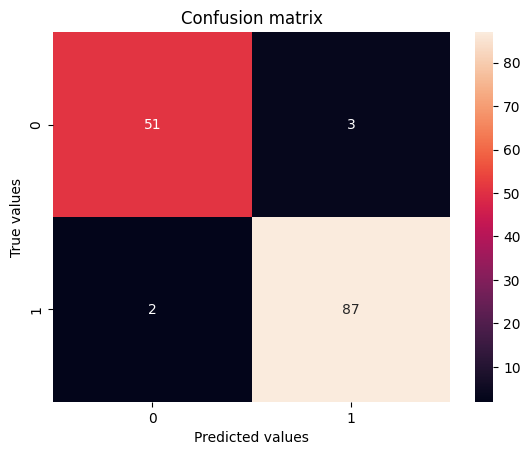

In [13]:
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion matrix')
plt.xlabel('Predicted values')
plt.ylabel('True values')
plt.show()

### Model Error Analysis
Despite the high accuracy, the confusion matrix analysis showed that the model more often makes False Positive errors (predicts a benign tumor when it is malignant) than False Negative errors.

In the context of medical diagnostics, this is a critical point, as missing a malignant tumor (FP) is far more dangerous than a false alarm (FN). To improve the model in the future, the data can be scaled.

## Implementation of Normalization Using a Custom Class

In [14]:
class Min_Max_Scaler():
    def __init__(self):
        self.min_ = None
        self.max_ = None

    def fit(self, X):
        self.min_ = X.min(axis=0)
        self.max_ = X.max(axis=0)

    def transform(self, X):
        return (X - self.min_) / (self.max_ - self.min_)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

In [15]:
sc = Min_Max_Scaler()
sc.fit(X_train)
sc.min_, sc.max_

(array([7.691e+00, 9.710e+00, 4.792e+01, 1.704e+02, 5.263e-02, 1.938e-02,
        0.000e+00, 0.000e+00, 1.167e-01, 4.996e-02, 1.115e-01, 3.602e-01,
        7.570e-01, 6.802e+00, 1.713e-03, 2.252e-03, 0.000e+00, 0.000e+00,
        7.882e-03, 8.948e-04, 8.678e+00, 1.202e+01, 5.449e+01, 2.236e+02,
        7.117e-02, 2.729e-02, 0.000e+00, 0.000e+00, 1.565e-01, 5.504e-02]),
 array([2.811e+01, 3.928e+01, 1.885e+02, 2.501e+03, 1.634e-01, 3.114e-01,
        4.268e-01, 2.012e-01, 3.040e-01, 9.744e-02, 2.873e+00, 4.885e+00,
        2.198e+01, 5.422e+02, 3.113e-02, 1.354e-01, 3.960e-01, 5.279e-02,
        6.146e-02, 2.984e-02, 3.604e+01, 4.954e+01, 2.512e+02, 4.254e+03,
        2.184e-01, 9.379e-01, 9.608e-01, 2.910e-01, 6.638e-01, 1.730e-01]))

In [16]:
X_train_sc = sc.transform(X_train)
X_test_sc = sc.transform(X_test)

pd.DataFrame(X_train_sc, columns=data.feature_names).head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,0.254616,0.115320,0.241642,0.148245,0.152749,0.061331,0.052952,0.058201,0.090763,0.123210,...,0.180615,0.093817,0.167302,0.087684,0.169734,0.095991,0.123439,0.184399,0.146659,0.119617
1,0.279593,0.365573,0.289657,0.165751,0.523337,0.436682,0.338566,0.406163,0.506674,0.490522,...,0.282582,0.470149,0.298968,0.154029,0.585682,0.393483,0.531432,0.704811,0.398186,0.473550
2,0.258044,0.290159,0.257931,0.152235,0.188499,0.204130,0.095056,0.093588,0.377469,0.190185,...,0.199254,0.335554,0.212597,0.098824,0.150241,0.224586,0.166944,0.227079,0.323674,0.147762


In [17]:
pd.DataFrame(X_train, columns=data.feature_names).head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,12.89,13.12,81.89,515.9,0.06955,0.03729,0.02260,0.01171,0.1337,0.05581,...,13.62,15.54,87.40,577.0,0.09616,0.1147,0.1186,0.05366,0.2309,0.06915
1,13.40,20.52,88.64,556.7,0.11060,0.14690,0.14450,0.08172,0.2116,0.07325,...,16.41,29.66,113.30,844.4,0.15740,0.3856,0.5106,0.20510,0.3585,0.11090
2,12.96,18.29,84.18,525.2,0.07351,0.07899,0.04057,0.01883,0.1874,0.05899,...,14.13,24.61,96.31,621.9,0.09329,0.2318,0.1604,0.06608,0.3207,0.07247


In [18]:
scal = Min_Max_Scaler()
X_train_scal = scal.fit_transform(X_train)
X_test_scal = scal.transform(X_test)
X_train_scal[:2]

array([[0.2546158 , 0.11531958, 0.24164177, 0.14824509, 0.15274894,
        0.06133142, 0.0529522 , 0.0582008 , 0.09076348, 0.12320977,
        0.01510049, 0.02404526, 0.01686849, 0.01097875, 0.10259374,
        0.0841019 , 0.04171717, 0.11185831, 0.15506365, 0.04098089,
        0.18061545, 0.09381663, 0.16730212, 0.0876836 , 0.16973443,
        0.0959906 , 0.1234388 , 0.18439863, 0.14665878, 0.11961682],
       [0.27959254, 0.36557322, 0.28965713, 0.16575131, 0.52333664,
        0.43668242, 0.33856607, 0.40616302, 0.50667379, 0.49052233,
        0.10106826, 0.12606082, 0.11006926, 0.05018323, 0.12581161,
        0.15319795, 0.08717172, 0.25269937, 0.17111501, 0.10745132,
        0.28258168, 0.47014925, 0.29896802, 0.15402938, 0.58568227,
        0.39348349, 0.53143214, 0.704811  , 0.39818648, 0.47355036]])

In [19]:
X_train_scal.min(axis=0)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [20]:
X_train_scal.max(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [21]:
X_test_scal.min(axis=0)

array([-0.03477154,  0.0226581 , -0.02937829, -0.01154209,  0.1185339 ,
        0.05547565,  0.        ,  0.        , -0.0571276 ,  0.05686605,
        0.00184682,  0.00057461,  0.00067851,  0.00402131,  0.04949519,
        0.02556554,  0.        ,  0.        ,  0.03092687,  0.01120048,
       -0.02733718,  0.01252665, -0.02074119, -0.00952759,  0.11424302,
        0.03036426,  0.        ,  0.        ,  0.00019712,  0.03399457])

In [22]:
X_test_scal.max(axis=0)

array([0.85846516, 0.72404464, 0.87907241, 0.73268686, 0.76257109,
       1.11643038, 0.87956888, 0.91699801, 0.92845702, 0.68386689,
       0.42712294, 0.7814268 , 0.41831975, 0.36028898, 0.48703131,
       0.78219725, 0.76717172, 0.62928585, 1.32643996, 0.75885466,
       0.87025802, 0.93656716, 0.81088913, 0.79605002, 1.02852679,
       1.13188961, 1.30308077, 0.9975945 , 0.76384782, 1.29247202])

## Built-in Normalization Class Implementation

In [23]:
scaler = MinMaxScaler()
scaler.fit(X_train)
scaler.data_min_,scaler.data_max_

(array([7.691e+00, 9.710e+00, 4.792e+01, 1.704e+02, 5.263e-02, 1.938e-02,
        0.000e+00, 0.000e+00, 1.167e-01, 4.996e-02, 1.115e-01, 3.602e-01,
        7.570e-01, 6.802e+00, 1.713e-03, 2.252e-03, 0.000e+00, 0.000e+00,
        7.882e-03, 8.948e-04, 8.678e+00, 1.202e+01, 5.449e+01, 2.236e+02,
        7.117e-02, 2.729e-02, 0.000e+00, 0.000e+00, 1.565e-01, 5.504e-02]),
 array([2.811e+01, 3.928e+01, 1.885e+02, 2.501e+03, 1.634e-01, 3.114e-01,
        4.268e-01, 2.012e-01, 3.040e-01, 9.744e-02, 2.873e+00, 4.885e+00,
        2.198e+01, 5.422e+02, 3.113e-02, 1.354e-01, 3.960e-01, 5.279e-02,
        6.146e-02, 2.984e-02, 3.604e+01, 4.954e+01, 2.512e+02, 4.254e+03,
        2.184e-01, 9.379e-01, 9.608e-01, 2.910e-01, 6.638e-01, 1.730e-01]))

In [24]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled[:1]

array([[0.2546158 , 0.11531958, 0.24164177, 0.14824509, 0.15274894,
        0.06133142, 0.0529522 , 0.0582008 , 0.09076348, 0.12320977,
        0.01510049, 0.02404526, 0.01686849, 0.01097875, 0.10259374,
        0.0841019 , 0.04171717, 0.11185831, 0.15506365, 0.04098089,
        0.18061545, 0.09381663, 0.16730212, 0.0876836 , 0.16973443,
        0.0959906 , 0.1234388 , 0.18439863, 0.14665878, 0.11961682]])

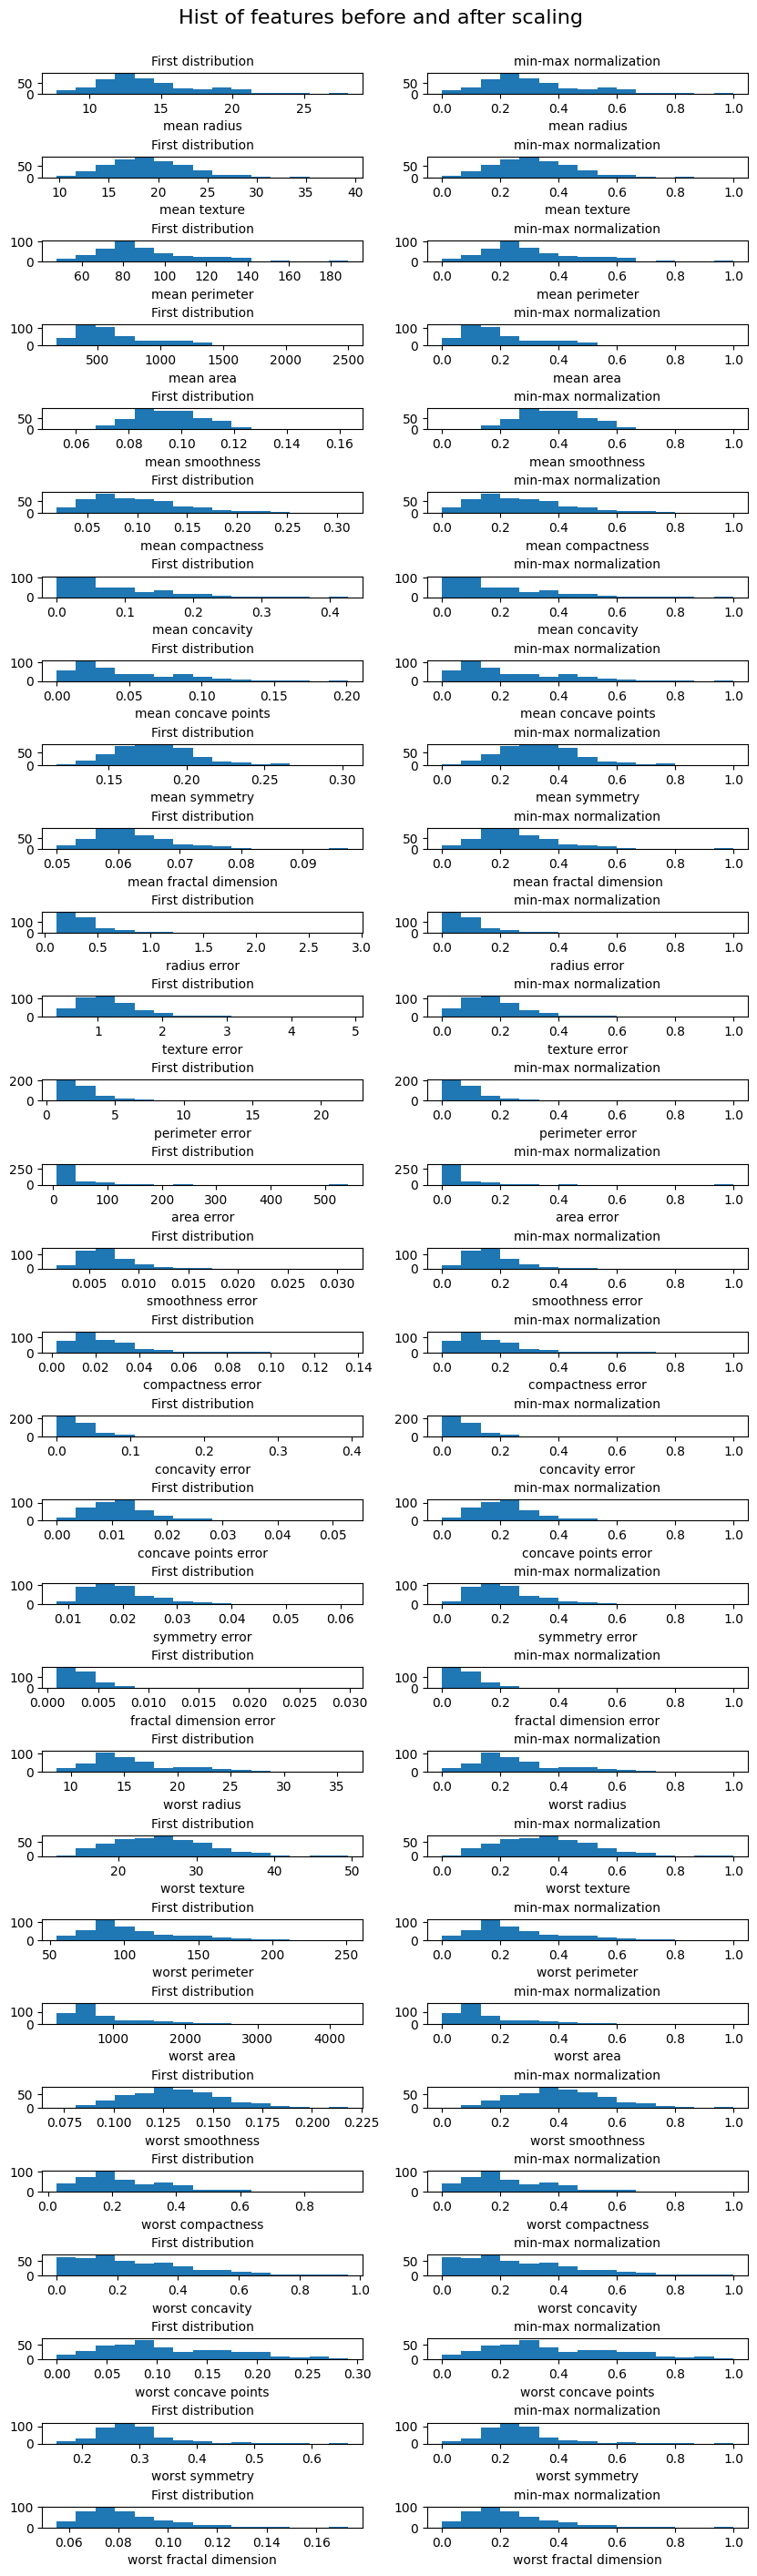

In [45]:
f, ax = plt.subplots(nrows = X_train.shape[1], ncols = 2, figsize=(10,35))
f.suptitle("Hist of features before and after scaling ",y = 0.9,fontsize=16)
for i in range(0,X_train.shape[1]):
    ax[i][0].hist(X_train[:, i], bins = 15)
    ax[i][0].set_title('First distribution',fontsize=10)
    ax[i][0].set_xlabel(data.feature_names[i])

    ax[i][1].hist(X_train_scaled[:, i], bins = 15)
    ax[i][1].set_title('min-max normalization',fontsize=10)
    ax[i][1].set_xlabel(data.feature_names[i])
f.subplots_adjust(hspace=3)

plt.show()

## Model Training on Scaled Data

In [26]:
model_ln = LogisticRegression()

In [27]:
model_ln.fit(X_train_scaled, y_train)

LogisticRegression()

In [28]:
model_ln.coef_, model_ln.intercept_

(array([[-1.71621643, -1.64503237, -1.66284027, -1.42740759, -0.64636508,
         -0.26043664, -1.2041863 , -1.95065969, -0.48553724,  0.84804835,
         -1.14524077, -0.06695901, -0.83567697, -0.74483001, -0.038253  ,
          0.64176641,  0.23509085, -0.25380244,  0.22970929,  0.63492818,
         -2.13131088, -2.21110139, -1.8814488 , -1.50831071, -1.37435871,
         -0.6705115 , -1.56588316, -2.33010655, -1.32465885, -0.20716885]]),
 array([8.23955273]))

In [29]:
pd.DataFrame(np.abs(model_ln.coef_[0]), data.feature_names, columns=['coef']).sort_values(by='coef', ascending=False)

,coef
worst concave points,2.330107
worst texture,2.211101
worst radius,2.131311
mean concave points,1.950660
worst perimeter,1.881449
mean radius,1.716216
mean perimeter,1.662840
mean texture,1.645032
worst concavity,1.565883
worst area,1.508311


## Top 3 Most Significant Features:

1) worst concave points

2) worst texture

3) worst radius

## Performance Metrics on Scaled Data

In [30]:
y_test_pred_scaled = model_ln.predict(X_test_scaled)
accuracy_scaled, f1_scaled = metrics.accuracy_score(y_test, y_test_pred_scaled), metrics.f1_score(y_test, y_test_pred_scaled)
accuracy_scaled, f1_scaled

(0.9790209790209791, 0.9832402234636871)

## Metrics on Raw Data

In [31]:
accuracy, f1

(0.965034965034965, 0.9720670391061452)

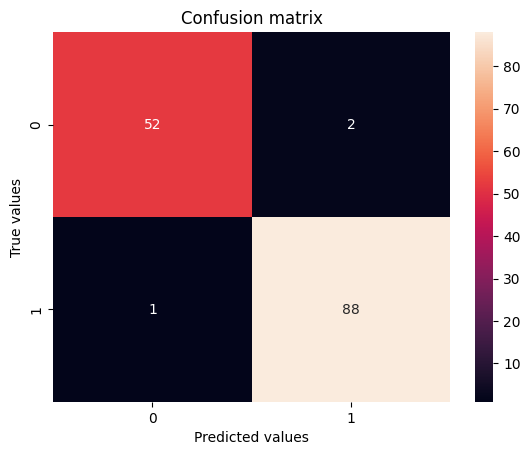

In [32]:
cm2 = confusion_matrix(y_test, y_test_pred_scaled)
sns.heatmap(cm2, annot=True, fmt='d')
plt.title('Confusion matrix')
plt.xlabel('Predicted values')
plt.ylabel('True values')
plt.show()

The model performed better on the scaled data, making fewer errors.

Before:

FP = 3

FN = 2

After:

FP = 2

FN = 1

### Logistic Regression Model on Min-Max Scaled Data Using the Pipeline Class

In [33]:
pipe = Pipeline(steps =[('scaler', MinMaxScaler()),('model', LogisticRegression())])
pipe

Pipeline(steps=[('scaler', MinMaxScaler()), ('model', LogisticRegression())])

In [34]:
pipe.fit(X_train, y_train)
pipe.named_steps['model'].intercept_, pipe.named_steps['model'].coef_

(array([8.23955273]),
 array([[-1.71621643, -1.64503237, -1.66284027, -1.42740759, -0.64636508,
         -0.26043664, -1.2041863 , -1.95065969, -0.48553724,  0.84804835,
         -1.14524077, -0.06695901, -0.83567697, -0.74483001, -0.038253  ,
          0.64176641,  0.23509085, -0.25380244,  0.22970929,  0.63492818,
         -2.13131088, -2.21110139, -1.8814488 , -1.50831071, -1.37435871,
         -0.6705115 , -1.56588316, -2.33010655, -1.32465885, -0.20716885]]))

In [35]:
y_test_pred_pipe = pipe.predict(X_test)
y_test_pred_pipe[:5]

array([1, 0, 0, 1, 1])

In [36]:
metrics.accuracy_score(y_test, y_test_pred_pipe), accuracy_scaled

(0.9790209790209791, 0.9790209790209791)

In [37]:
metrics.f1_score(y_test, y_test_pred_pipe), f1_scaled

(0.9832402234636871, 0.9832402234636871)

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((426, 30), (143, 30), (426,), (143,))

In [39]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [40]:
model.intercept_, model.coef_

(np.float64(3.0018078066482357),
 array([ 2.34866411e-01, -2.46839171e-03, -3.25089250e-02, -1.64858367e-04,
        -6.39577460e-02,  5.03711313e+00, -1.13330230e-02, -6.17662144e+00,
         4.11318652e-01, -5.09448207e+00, -5.39408205e-01,  2.09055279e-02,
         1.30951166e-02,  1.51157528e-03, -2.04809335e+01,  2.90771809e+00,
         3.72254332e+00, -1.71255590e+01,  1.30233472e+00,  2.15877319e+00,
        -1.99200691e-01, -1.15347947e-02,  1.03878665e-02,  8.29164431e-04,
         6.13521807e-01, -7.61878573e-01, -8.52468315e-01,  1.48626243e+00,
        -1.05305973e+00, -1.72754163e+00]))

In [41]:
y_pred = model.predict(X_test)
y_pred

array([ 0.62146212,  0.19849906,  0.27416519,  1.13196807,  1.1201975 ,
       -0.65832448, -0.05888011,  0.43293341,  0.25540949,  0.96541474,
        0.77613543,  0.32486139,  0.90537365,  0.38364338,  0.93217848,
        0.18069198,  0.92465377,  1.19340235,  1.43493468,  0.01335516,
        0.6563777 ,  0.87175726, -0.43053822,  1.07858677,  0.95235005,
        0.83148475,  0.98115676,  0.84599039,  0.94831314, -0.20471322,
        1.01153244,  1.0469781 ,  0.80457539,  0.92777625,  1.06961736,
        0.8382285 ,  0.4769304 ,  0.63046388,  0.25983274,  0.75057537,
        1.15074081,  0.02292288,  0.96494069,  0.99698272,  0.50789479,
        0.65012214,  0.93596734,  0.99797142,  0.78748068,  1.01230437,
        0.20865587, -0.12331866,  0.52253576,  0.60960077,  1.02150647,
        0.80095064,  0.92358872, -0.34620317,  0.54363085,  1.05188349,
        0.92975313, -0.20642278, -0.35012463,  0.79509521,  0.90804962,
        0.53054802, -0.21281613, -0.16569036,  0.97362429,  0.81

In [42]:
r2 = metrics.r2_score(y_test, y_pred)
r2

0.7324078874665078

In [43]:
rmse = metrics.root_mean_squared_error(y_test, y_pred)
rmse

0.25077977006194996

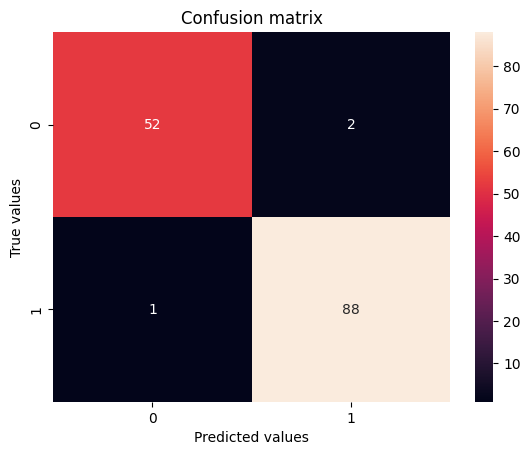

In [44]:
cm3 = confusion_matrix(y_test, y_test_pred_scaled)
sns.heatmap(cm3, annot=True, fmt='d')
plt.title('Confusion matrix')
plt.xlabel('Predicted values')
plt.ylabel('True values')
plt.show()

The Pipeline class did not change the performance quality of the previous model.